<a href="https://colab.research.google.com/github/KaiIkuta/fmjax/blob/main/fmjax_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install git+https://github.com/KaiIkuta/fmjax.git

  Cloning https://github.com/KaiIkuta/fmjax.git to /tmp/pip-req-build-7dfi1l04
  Running command git clone --filter=blob:none --quiet https://github.com/KaiIkuta/fmjax.git /tmp/pip-req-build-7dfi1l04
  Resolved https://github.com/KaiIkuta/fmjax.git to commit 154534c4f80cf64dfe6eadcccb63efa4837a7cda
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for fmjax: filename=fmjax-0.1.0-py3-none-any.whl size=2679 sha256=08427ab0900f901e7f11251ffccb928b3efea86bd0128451f2dcb8ac81145622
  Stored in directory: /tmp/pip-ephem-wheel-cache-m3li7utn/wheels/08/81/48/ba2e6f54caaf156b02c27189229557eee09cd385cb72cdd513
Successfully built fmjax
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [fmjax]


In [4]:
!pip install -U flax

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 533.9/533.9 kB 16.6 MB/s  0:00:00
  Attempting uninstall: flax
    Found existing installation: flax 0.11.2
    Uninstalling flax-0.11.2:
      Successfully uninstalled flax-0.11.2


Parameter initialization complete.
Step 00000 | Loss: 2.1079
Step 00500 | Loss: 0.1294
Step 01000 | Loss: 0.1907
Step 01500 | Loss: 0.1331
Step 02000 | Loss: 0.1096
Step 02500 | Loss: 0.2248
Step 03000 | Loss: 0.0932
Step 03500 | Loss: 0.1704
Step 04000 | Loss: 0.1030
Step 04500 | Loss: 0.1222
Step 05000 | Loss: 0.1088
Step 05500 | Loss: 0.1702
Step 06000 | Loss: 0.1393
Step 06500 | Loss: 0.1077
Step 07000 | Loss: 0.1828
Step 07500 | Loss: 0.0728
Step 08000 | Loss: 0.2053
Step 08500 | Loss: 0.1090
Step 09000 | Loss: 0.1844
Step 09500 | Loss: 0.2069
Step 10000 | Loss: 0.1119
Generated samples shape: (500, 2)


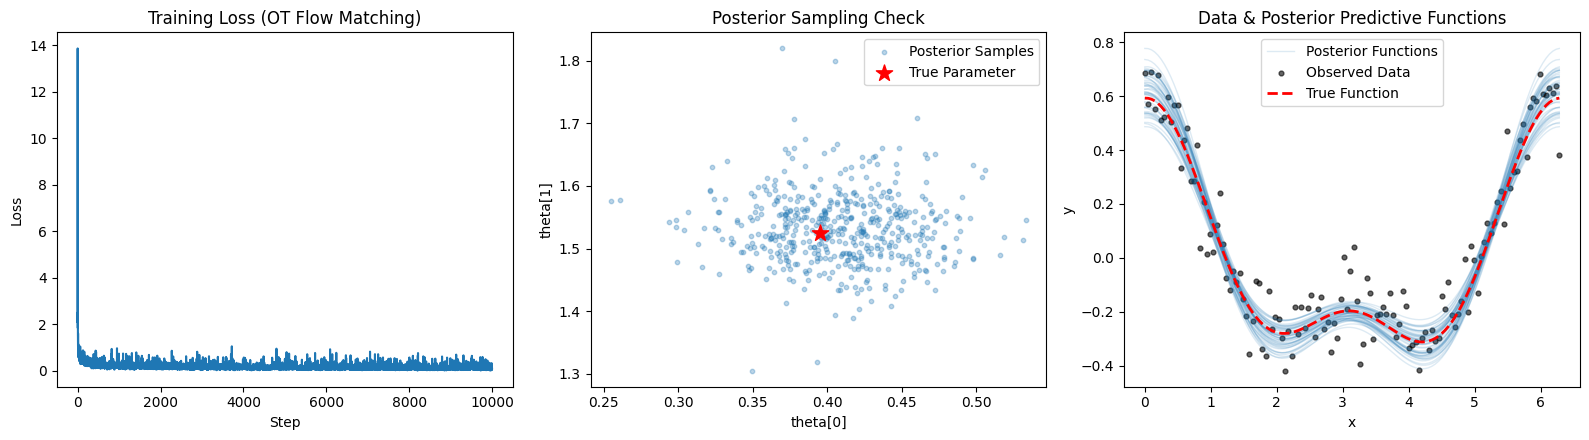

In [5]:
import jax
import jax.extend
import jax.numpy as jnp

# Compatibility patch for JAX v0.11.x and older Flax versions
if not hasattr(jax.core, "get_opaque_trace_state"):
    jax.core.get_opaque_trace_state = jax.extend.core.get_opaque_trace_state

import optax
from flax.training import train_state
import matplotlib.pyplot as plt

from fmjax import (
    ConditionalVectorFieldNetwork,
    ot_flow_matching_loss,
    train_step,
    sample_posterior,
)

# --- 1. Toy Data Generation (Inferring 2D parameters theta1 from 1D waveform context) ---
key = jax.random.PRNGKey(42)
batch_size = 64
seq_len = 128
param_dim = 2  # Dimension of target parameters to infer
grid = jnp.linspace(0, 2 * jnp.pi, seq_len)

def forward_model(theta, grid):
    """Noise-free forward model mapping parameters theta (B, 2) to 1D signals (B, seq_len)."""
    g = grid[None, :]
    return (
        theta[:, 0:1] * jnp.sin(g + theta[:, 1:2])
        + 0.5 * theta[:, 0:1] * jnp.cos(2.0 * g)
    )

def make_toy_batch(rng, batch_size, seq_len):
    k1, k2 = jax.random.split(rng)
    # True parameters theta1 ~ N(0, I): shape = (B, param_dim)
    theta1 = jax.random.normal(k1, (batch_size, param_dim))

    # Observed context: 2D shape (B, seq_len) as expected by ContextEncoder1D
    noise = 0.1 * jax.random.normal(k2, (batch_size, seq_len))
    context = forward_model(theta1, grid) + noise
    return theta1, context

# --- 2. Network and TrainState Initialization ---
key, init_key, data_key = jax.random.split(key, 3)
theta_dummy, context_dummy = make_toy_batch(data_key, batch_size=4, seq_len=seq_len)
t_init_dummy = jnp.ones((4, 1))  # Shape (B, 1) for model.__call__

model = ConditionalVectorFieldNetwork(out_dim=param_dim)
variables = model.init(init_key, theta_dummy, t_init_dummy, context_dummy)

tx = optax.adamw(learning_rate=1e-3)
state = train_state.TrainState.create(
    apply_fn=model.apply,
    params=variables["params"],
    tx=tx,
)
print("Parameter initialization complete.")

# --- 3. Training Loop with train_step ---
num_steps = 10000
losses = []

for step in range(num_steps + 1):
    key, k_data, k_theta0, k_t = jax.random.split(key, 4)
    theta1_batch, context_batch = make_toy_batch(k_data, batch_size, seq_len)

    # Base distribution noise theta0: (B, param_dim), time t: (B,)
    theta0_batch = jax.random.normal(k_theta0, (batch_size, param_dim))
    t_batch = jax.random.uniform(k_t, (batch_size,))

    state, loss = train_step(state, theta1_batch, theta0_batch, t_batch, context_batch)
    losses.append(float(loss))

    if step % 500 == 0:
        print(f"Step {step:05d} | Loss: {loss:.4f}")

# --- 4. Posterior Sampling via sample_posterior ---
key, test_data_key, sample_key = jax.random.split(key, 3)
theta_true, context_obs = make_toy_batch(test_data_key, batch_size=1, seq_len=seq_len)

samples = sample_posterior(
    state,
    sample_key,
    num_samples=500,
    context_single=context_obs,  # Shape (1, seq_len)
    param_dim=param_dim,
)
print("Generated samples shape:", samples.shape)

# --- 5. Visualization (Loss, Posterior Space, and Function Space) ---
samples_np = jnp.asarray(samples)
y_post_all = forward_model(samples_np, grid)  # (num_samples, seq_len)
y_true = forward_model(theta_true, grid)[0]   # (seq_len,)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Panel 1: Training Loss
axes[0].plot(losses)
axes[0].set_title("Training Loss (OT Flow Matching)")
axes[0].set_xlabel("Step")
axes[0].set_ylabel("Loss")

# Panel 2: Posterior Samples in Parameter Space
axes[1].scatter(samples_np[:, 0], samples_np[:, 1], alpha=0.3, s=10, label="Posterior Samples")
axes[1].scatter(theta_true[0, 0], theta_true[0, 1], color="red", marker="*", s=150, label="True Parameter")
axes[1].set_title("Posterior Sampling Check")
axes[1].set_xlabel("theta[0]")
axes[1].set_ylabel("theta[1]")
axes[1].legend()

# Panel 3: Observed Data vs. Reconstructed Functions from Posterior
for i in range(50):
    axes[2].plot(
        grid,
        y_post_all[i],
        color="tab:blue",
        alpha=0.15,
        linewidth=1.0,
        label="Posterior Functions" if i == 0 else None,
    )
axes[2].scatter(grid, context_obs[0], color="black", s=12, alpha=0.6, label="Observed Data")
axes[2].plot(grid, y_true, color="red", linestyle="--", linewidth=2.0, label="True Function")
axes[2].set_title("Data & Posterior Predictive Functions")
axes[2].set_xlabel("x")
axes[2].set_ylabel("y")
axes[2].legend()

plt.tight_layout()
plt.show()